<center>
<img src="../../img/ods_stickers.jpg">


[Материал разработат на основе электронного ресурса](Ю.Кашницкого.https://mlcourse.ai/book/index.html)

# <center>Обучение без учителя
## <center> Кластеризация. Метод k-средних (k-means)

Метод k-means – это один из наиболее популярных методов кластеризации. Основная идея метода заключается в том, что на каждой итерации пересчитывается центр масс (центроид) для каждого кластера, полученного на предыдущем шаге, затем объекты снова разбиваются на кластеры согласно тому, какой из новых центроидов находится ближе.

Более формально, алгоритм принимает на вход выборку $X_1, \dots, X_N$ и параметр $k$, указывающий необходимое число кластеров. Выходом алгоритма является набор из $k$ центроидов $\{\mu_1, \dots, \mu_k\}$, с помощью которых кластеризация осуществляется путём отнесения каждого объекту к ближайшему центроиду. Все точки внутри одного кластера ближе к центроиду этого кластера, чем к центроиду любого другого кластера.

Метод может быть сформулирован как задача оптимизации, а именно, минимизации суммарного квадратичного отклонения точек кластеров от центров этих кластеров по центроидам и кластерам:
$$\sum_{i=1}^k \sum_{X_n \in C_i} ||X_n - \mu_i||^2 \rightarrow \min, \text{где $C_i$ - это $i$-ый кластер, $\mu_i$ - это центр масс кластера $C_i$.}$$

Решение такой задачи оптимизации является NP-трудной задачей, однако существует простой итеративный алгоритм, позволяющий найти локальный минимум указанного функционала. Алгоритм представляет собой последовательное чередование двух шагов до сходимости. 

Предположим, что как-то (например, случайно) выбраны начальные положения центроидов $\mu_1, \dots, \mu_k$.

1) *Этап кластеризациu.* На данном этапе происходит кластеризация выборки, как было описано выше: каждый объект относится к кластеру ближайшего к нему центроида. Формально, $$C_i = \{X_n : ||X_n - \mu_i|| \leq ||X_n - \mu_j||, \text{ для всех $j \in \{1, \dots, k\}$}\}.$$

2) *Этап обновления центроидов.* На данном этапе центроиды пересчитываются, как центры масс только что построенных кластеров. Формально, $$\mu_i = \frac{1}{|C_i|}\sum_{X_n \in C_i} X_n.$$

Этот процесс продолжается, пока центроиды и кластеризация продолжают изменяться. Алгоритм гарантированно сходится, однако не гарантируется достижение глобального минимума – а только одного из локальных минимумов. Другим недостатком алгоритма является то, что итоговая кластеризация зависит от выбора исходных центров кластеров. На практике алгоритм запускается несколько раз из различных начальных приближений, а полученные результаты некоторым образом усредняются. Стоит также отметить, что число кластеров необходимо знать заранее. Существуют различные эвристики, позволяющие выбирать в некотором смысле оптимальное число кластеров.

### Пример: кластеризация игроков NBA

Про <a href="http://www.databasebasketball.com/about/aboutstats.htm">признаки</a> игроков.

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt

nba = pd.read_csv("../../data/nba_2013.csv")
nba.head(3)

,player,pos,age,bref_team_id,g,gs,mp,fg,fga,fg.,...,drb,trb,ast,stl,blk,tov,pf,pts,season,season_end
0,Quincy Acy,SF,23,TOT,63,0,847,66,141,0.468,...,144,216,28,23,26,30,122,171,2013-2014,2013
1,Steven Adams,C,20,OKC,81,20,1197,93,185,0.503,...,190,332,43,40,57,71,203,265,2013-2014,2013
2,Jeff Adrien,PF,27,TOT,53,12,961,143,275,0.520,...,204,306,38,24,36,39,108,362,2013-2014,2013


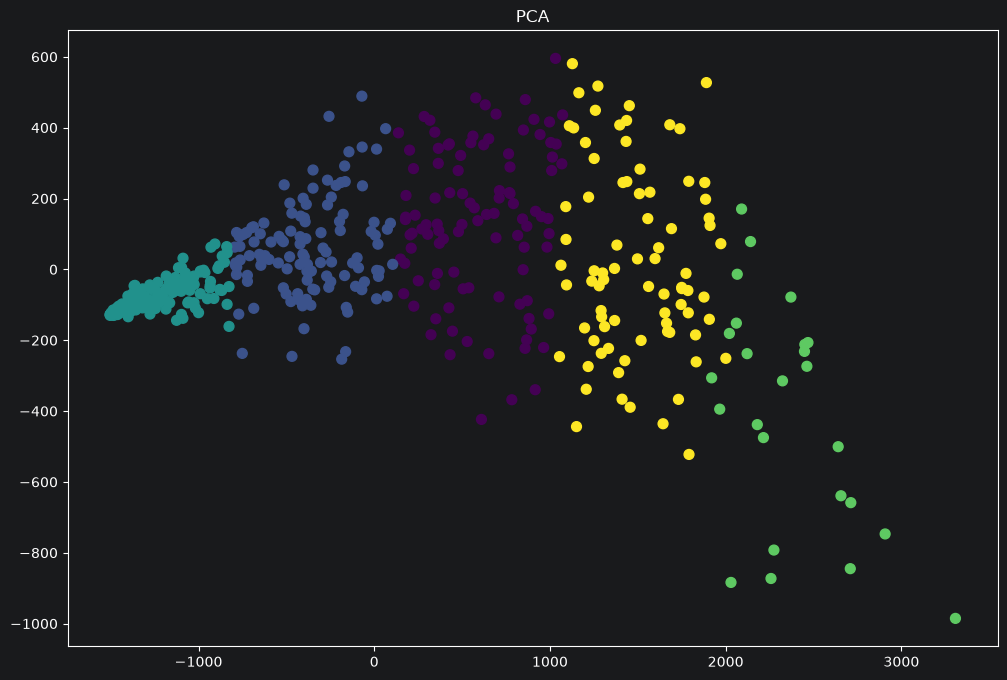

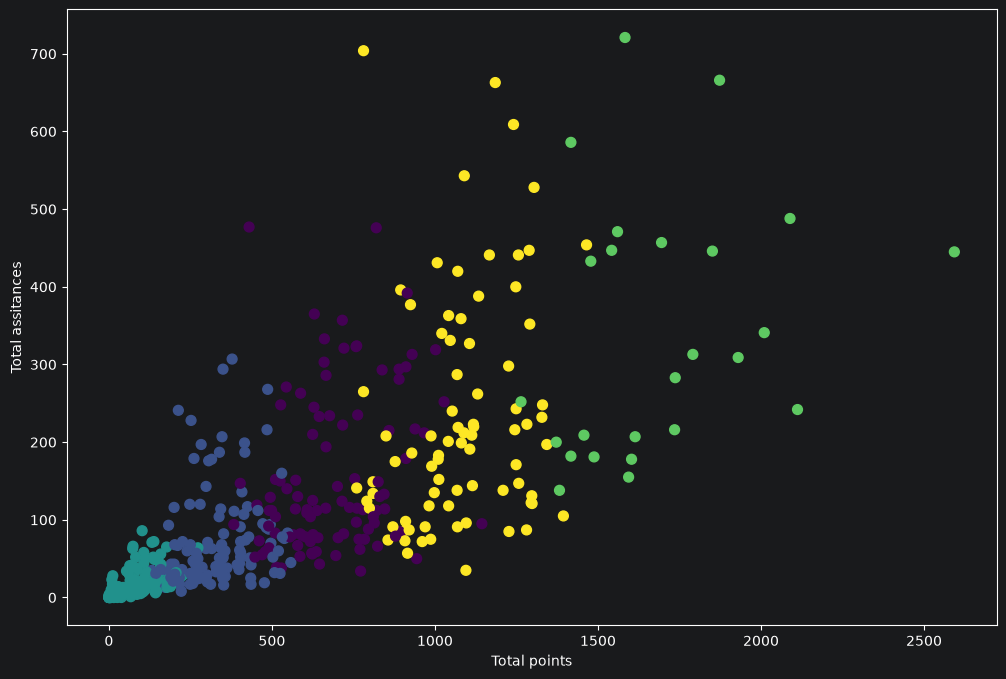

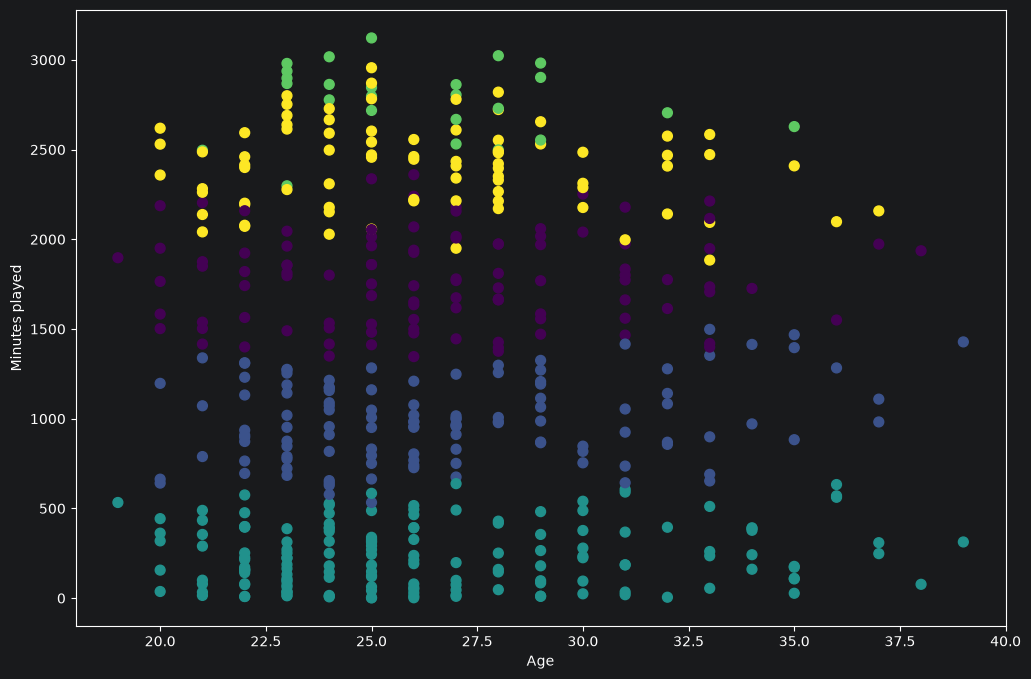

In [2]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

kmeans = KMeans(n_clusters=5, random_state=1)
numeric_cols = nba._get_numeric_data().dropna(axis=1)
kmeans.fit(numeric_cols)


# Визуализация с использованием PCA
pca = PCA(n_components=2)
res = pca.fit_transform(numeric_cols)
plt.figure(figsize=(12,8))
plt.scatter(res[:,0], res[:,1], c=kmeans.labels_, s=50, cmap='viridis')
plt.title('PCA')

# Визуализация с использованием двух функций: общее количество очков и общее количество передач.
plt.figure(figsize=(12,8))
plt.scatter(nba['pts'], nba['ast'], c=kmeans.labels_, s=50, cmap='viridis')
plt.xlabel('Total points')
plt.ylabel('Total assitances')

# Визуализация с использованием двух функций: возраст и количество сыгранных минут.
plt.figure(figsize=(12,8))
plt.scatter(nba['age'], nba['mp'], c=kmeans.labels_, s=50, cmap='viridis')
plt.xlabel('Age')
plt.ylabel('Minutes played');

### Инициализация центроидов

Метод `sklearn.KMeans` содержит параметры `n_init` (число запусков из различных начальных приближений) и `init`. Есть три способа инициализации центроидов:
- `k-means++` – "умная" инициализация центроидов для ускорения сходимости.
- `random` – случайная инициализация центроидов.
- `ndarray` – заданная инициализация центроидов.

## Сжатие изображений с K-means

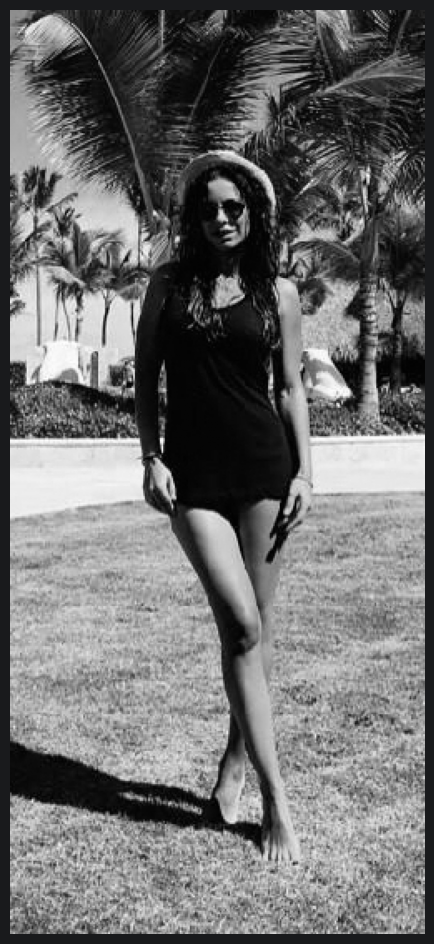

In [3]:
import matplotlib.image as mpimg

img = mpimg.imread('../../img/woman.jpg')[..., 1]
plt.figure(figsize = (20, 12))
plt.axis('off')
plt.imshow(img, cmap='gray');

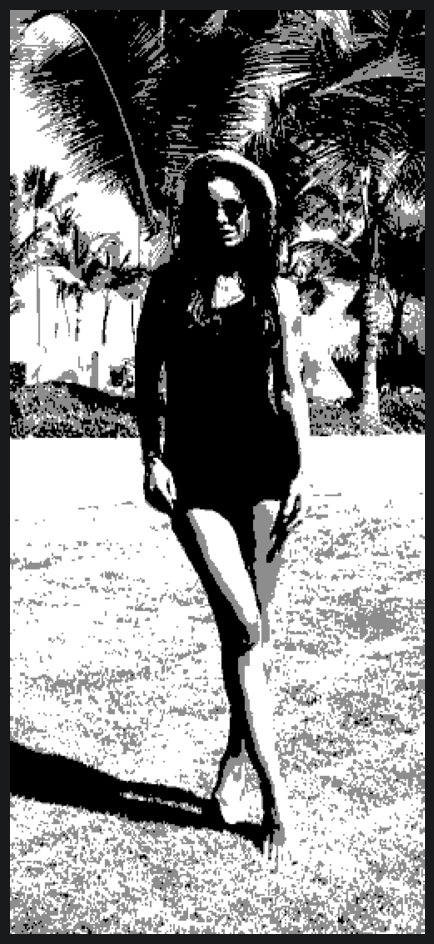

In [4]:
from scipy.stats import randint
from sklearn.cluster import MiniBatchKMeans

X = img.reshape((-1, 1))
k_means = MiniBatchKMeans(n_clusters=3)
k_means.fit(X) 
values = k_means.cluster_centers_
labels = k_means.labels_
img_compressed = values[labels].reshape(img.shape)
plt.figure(figsize = (20, 12))
plt.axis('off')
plt.imshow(img_compressed, cmap = 'gray');

# Нахождение тем в текстах

**Применим KMeans для кластеризации текстов из 4 новостных категорий.**

In [5]:
from time import time

from sklearn import metrics
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfTransformer, TfidfVectorizer
from sklearn.preprocessing import Normalizer

categories = [
    'alt.atheism',
    'talk.religion.misc',
    'comp.graphics',
    'sci.space']

print("Загрузка набора данных из 20 групп новостей для категорий:")
print(categories)

dataset = fetch_20newsgroups(subset='all', categories=categories,
                             shuffle=True, random_state=42)

print("%d documents" % len(dataset.data))
print("%d categories" % len(dataset.target_names))

labels = dataset.target
true_k = np.unique(labels).shape[0]

Загрузка набора данных из 20 групп новостей для категорий:
['alt.atheism', 'talk.religion.misc', 'comp.graphics', 'sci.space']
3387 documents
4 categories


**Закодируем тексты с помощью TF-IDF признаков.**

In [6]:
print("Извлечение функций из набора обучающих данных с помощью разреженного векторизатора:")
vectorizer = TfidfVectorizer(max_df=0.5, max_features=1000,
                             min_df=2, stop_words='english')

X = vectorizer.fit_transform(dataset.data)
print("n_образцов: %d, n_объектов: %d" % X.shape)

Извлечение функций из набора обучающих данных с помощью разреженного векторизатора:
n_образцов: 3387, n_объектов: 1000


**И применим к получившимся векторам метод $k$ средних.**

In [7]:
km = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)

print("Clustering sparse data with %s" % km)
t0 = time()
km.fit(X)

print("Homogeneity: %0.3f" % metrics.homogeneity_score(labels, km.labels_))
print("Completeness: %0.3f" % metrics.completeness_score(labels, km.labels_))
print("V-measure: %0.3f" % metrics.v_measure_score(labels, km.labels_))
print("Adjusted Rand-Index: %.3f"
      % metrics.adjusted_rand_score(labels, km.labels_))
print("Silhouette Coefficient: %0.3f"
      % metrics.silhouette_score(X, km.labels_, sample_size=1000))

order_centroids = km.cluster_centers_.argsort()[:, ::-1]

Clustering sparse data with KMeans(max_iter=100, n_clusters=4, n_init=1)
Homogeneity: 0.540
Completeness: 0.595
V-measure: 0.566
Adjusted Rand-Index: 0.548
Silhouette Coefficient: 0.016


**Выведем слова, соответствующие самым весомым компонентам центров кластеров.**

In [8]:
# terms = vectorizer.get_feature_names()
# for i in range(true_k):
#     print("Cluster %d:" % (i + 1), end='')
#     for ind in order_centroids[i, :10]:
#         print(' %s' % terms[ind], end='')
#     print()

AttributeError: 'TfidfVectorizer' object has no attribute 'get_feature_names'

## Кластеризация рукописных цифр

In [9]:
from sklearn.datasets import load_digits

digits = load_digits()

X, y = digits.data, digits.target

In [10]:
kmeans = KMeans(n_clusters=10)
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",10
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](10, 64

In [11]:
from sklearn.metrics import adjusted_rand_score

adjusted_rand_score(y, kmeans.predict(X))

0.6697693292166516

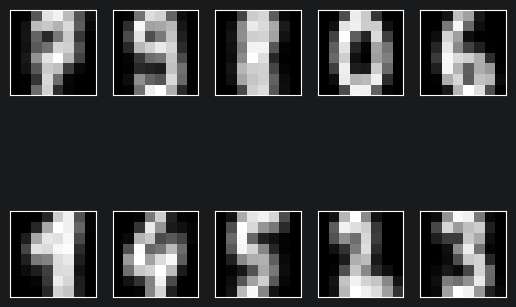

In [12]:
_, axes = plt.subplots(2, 5)
for ax, center in zip(axes.ravel(), kmeans.cluster_centers_):
    ax.matshow(center.reshape(8, 8), cmap=plt.cm.gray)
    ax.set_xticks(())
    ax.set_yticks(())

## Полезные ссылки
- <a href="https://en.wikipedia.org/wiki/K-means_clustering">k-means</a> на Википедии
- <a href="">Статья</a> про нечеткую кластеризацию городов по социально-экономическим показателям на Хабрахабре

## Задание:

1. Произведите методом k-means кластеризацию вин (датасет возьмите из третьей работы). Произведите разные варианты инициализации центров. Сравните результат. 
2. Выберите черно-белое и цветное изображение. Сожмите изображение с помощью метода K-means. 
3. Применим KMeans для кластеризации текстов.  Загрузите «KMeans.zip» отсюда (http://cmj4.web.rice.edu/KMeans.zip). 
Поместите его в каталог KMeans и разархивируйте. Помимо прочего, это создаст каталог «20_Newsgroups», содержащий   набор данных «20Newsgroups». 
Это набор из примерно 20 000 сообщений в 20 различных группах новостей (это что-то вроде блогов 1990-х годов). Каталог «20_newsgroups» будет иметь 
20 подкаталогов, каждый из которых соответствует группе новостей. 
В каждом подкаталоге около 1000 файлов, каждый из которых представляет собой публикацию.
Произведите кластеризацию по 20 кластерам. Оцените, насколько точно ваша кластеризация совпадает с классификацией, произведенной разработчику этого датасета.

## Решение задания

### 1. Кластеризация вин

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

wine = pd.read_csv('../../data/wine.csv')
y_wine = wine['quality'].values
X_wine = StandardScaler().fit_transform(wine.drop(columns='quality'))
k = len(np.unique(y_wine))
print(k, X_wine.shape)

6 (1599, 11)


In [14]:
rng = np.random.RandomState(1)
manual_centers = X_wine[rng.choice(len(X_wine), k, replace=False)]

inits = {
    'k-means++': 'k-means++',
    'random': 'random',
    'ndarray': manual_centers
}

rows = []
for name, init in inits.items():
    km = KMeans(n_clusters=k, init=init, n_init=1, random_state=1)
    km.fit(X_wine)
    rows.append({
        'init': name,
        'Homogeneity': metrics.homogeneity_score(y_wine, km.labels_),
        'Completeness': metrics.completeness_score(y_wine, km.labels_),
        'V-measure': metrics.v_measure_score(y_wine, km.labels_),
        'Adjusted Rand-Index': metrics.adjusted_rand_score(y_wine, km.labels_),
        'Silhouette Coefficient': metrics.silhouette_score(X_wine, km.labels_)
    })

pd.DataFrame(rows).set_index('init').round(3)

,Homogeneity,Completeness,V-measure,Adjusted Rand-Index,Silhouette Coefficient
init,,,,,
k-means++,0.122,0.090,0.103,0.077,0.181
random,0.123,0.090,0.104,0.077,0.180
ndarray,0.111,0.077,0.091,0.056,0.150


### 2. Сжатие изображений

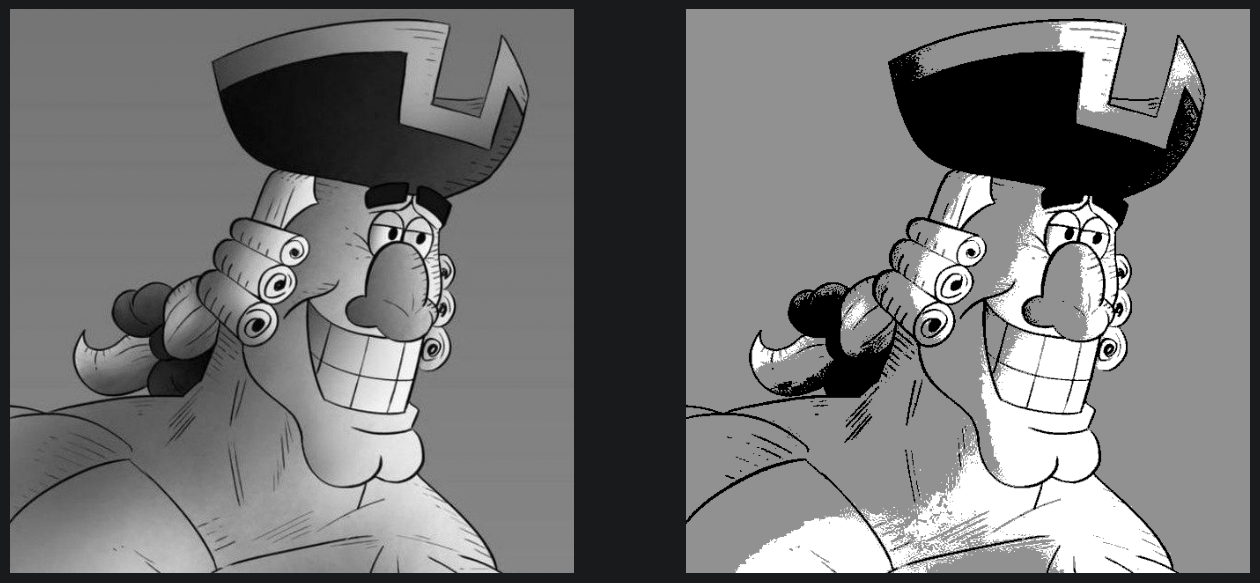

In [15]:
import matplotlib.image as mpimg
from sklearn.cluster import MiniBatchKMeans

img_gray = mpimg.imread('../../img/livsi_gray.jpg')[..., 1]
X = img_gray.reshape((-1, 1))
k_means = MiniBatchKMeans(n_clusters=3, random_state=1)
k_means.fit(X)
values = k_means.cluster_centers_
labels = k_means.labels_
img_gray_compressed = values[labels].reshape(img_gray.shape)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(img_gray, cmap='gray')
plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(img_gray_compressed, cmap='gray');

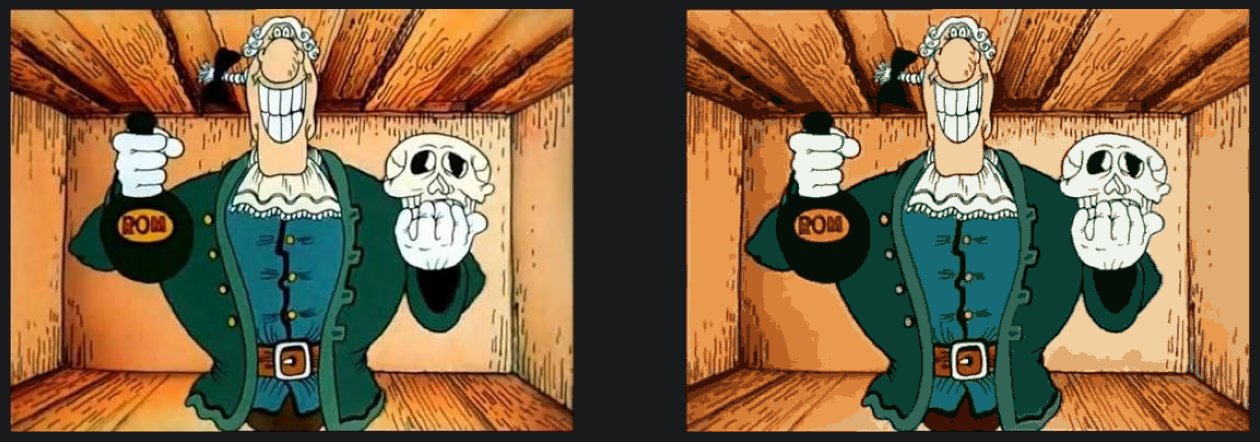

In [18]:
img_color = mpimg.imread('../../img/livsi.jpg')
X = img_color.reshape((-1, 3))
k_means = MiniBatchKMeans(n_clusters=16, random_state=1)
k_means.fit(X)
values = k_means.cluster_centers_
labels = k_means.labels_
img_color_compressed = values[labels].reshape(img_color.shape).astype(np.uint8)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.axis('off')
plt.imshow(img_color)
plt.subplot(1, 2, 2)
plt.axis('off')
plt.imshow(img_color_compressed);

### 3. Кластеризация текстов 20 Newsgroups

In [19]:
import os
from time import time
from sklearn.feature_extraction.text import TfidfVectorizer

path = 'Kmeans/20_newsgroups'
texts = []
labels_text = []
for group in sorted(os.listdir(path)):
    group_path = os.path.join(path, group)
    if not os.path.isdir(group_path):
        continue
    for file_name in os.listdir(group_path):
        with open(os.path.join(group_path, file_name), encoding='latin-1') as f:
            texts.append(f.read())
        labels_text.append(group)

labels_text = np.array(labels_text)
labels = pd.factorize(labels_text)[0]
true_k = len(np.unique(labels))
print(len(texts), true_k)

19997 20


In [20]:
vectorizer = TfidfVectorizer(max_df=0.5, max_features=1000, min_df=2, stop_words='english')
X = vectorizer.fit_transform(texts)
print("n_образцов: %d, n_объектов: %d" % X.shape)

n_образцов: 19997, n_объектов: 1000


In [21]:
km = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1, random_state=1)

print("Clustering sparse data with %s" % km)
t0 = time()
km.fit(X)
print("done in %0.3fs" % (time() - t0))

print("Homogeneity: %0.3f" % metrics.homogeneity_score(labels, km.labels_))
print("Completeness: %0.3f" % metrics.completeness_score(labels, km.labels_))
print("V-measure: %0.3f" % metrics.v_measure_score(labels, km.labels_))
print("Adjusted Rand-Index: %.3f" % metrics.adjusted_rand_score(labels, km.labels_))
print("Silhouette Coefficient: %0.3f" % metrics.silhouette_score(X, km.labels_, sample_size=1000))

order_centroids = km.cluster_centers_.argsort()[:, ::-1]

Clustering sparse data with KMeans(max_iter=100, n_clusters=20, n_init=1, random_state=1)
done in 1.332s
Homogeneity: 0.423
Completeness: 0.485
V-measure: 0.452
Adjusted Rand-Index: 0.251
Silhouette Coefficient: 0.043


In [22]:
terms = vectorizer.get_feature_names_out()
for i in range(true_k):
    print("Cluster %d:" % (i + 1), end='')
    for ind in order_centroids[i, :10]:
        print(' %s' % terms[ind], end='')
    print()

Cluster 1: sci space graphics mit comp med eng harvard nntp posting
Cluster 2: windows comp os ms misc dos file motif microsoft files
Cluster 3: rec baseball sport autos game hockey car motorcycles team article
Cluster 4: gov nasa space jpl sci center article astro ames ohio
Cluster 5: mchp sni ap horus frank objective talk abortion morality atheism
Cluster 6: sys ibm mac hardware comp pc drive scsi card apple
Cluster 7: talk politics misc alt religion guns people state article ohio
Cluster 8: au oz cc comp sci state windows ohio university org
Cluster 9: culture soc turkish armenian soviet armenians politics mideast talk armenia
Cluster 10: forsale misc sale computers offer udel state rec ohio 00
Cluster 11: digex access pat space sci communications 0400 usa mail astro
Cluster 12: rutgers christian athos geneva god religion soc igor hedrick aramis
Cluster 13: state ohio cis mps sei cc zaphod magnus acs hp
Cluster 14: caltech gap keith sgi server nntp california institute technology jp